In [4]:
import sys 
import os
from tqdm import tqdm
import sglang as sgl
import json
from datetime import datetime
import supervision as sv
import cv2
import torch
from transformers import LlavaNextProcessor, LlavaNextForConditionalGeneration, AutoTokenizer, AutoConfig
from captum.attr import visualization
import matplotlib.pyplot as plt

# Add the project root directory to sys.path
project_root = os.path.abspath('..')  # Adjust this path if needed
sys.path.append(project_root)

from utils import load_images_and_combine
from utils import GeneratorOurs
from utils import Preprocess
from utils import GeneralizedRCNN

In [5]:
# load model
model_path = "llava-hf/llava-v1.6-mistral-7b-hf"
tokenizer_path = "llava-hf/llava-1.5-7b-hf"
processor_path = "llava-hf/llava-v1.6-mistral-7b-hf"
config = AutoConfig.from_pretrained(model_path, output_attentions=True)
model = LlavaNextForConditionalGeneration.from_pretrained(model_path, torch_dtype=torch.float16, low_cpu_mem_usage=True, config=config) 
tokenizer = AutoTokenizer.from_pretrained(tokenizer_path)
processor = LlavaNextProcessor.from_pretrained(processor_path)

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [6]:
model = model.to('cuda:2')

OutOfMemoryError: CUDA out of memory. Tried to allocate 32.00 MiB. GPU 2 has a total capacty of 47.54 GiB of which 29.19 MiB is free. Process 34248 has 2.59 GiB memory in use. Process 76050 has 2.52 GiB memory in use. Process 78708 has 2.48 GiB memory in use. Process 255357 has 714.00 MiB memory in use. Process 274711 has 35.93 GiB memory in use. Process 367569 has 3.27 GiB memory in use. Of the allocated memory 2.96 GiB is allocated by PyTorch, and 56.50 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting max_split_size_mb to avoid fragmentation.  See documentation for Memory Management and PYTORCH_CUDA_ALLOC_CONF

In [ ]:
def image_qa(image_file, question):
    prompt = "[INST] <image>\n{question} [/INST]"
    if isinstance(image_file, str):
        image = cv2.imread(image_file)
    else:
        image = image_file

    inputs = processor(text=prompt, images=image, return_tensors="pt").to("cuda:2")

    # Generate
    outputs = model.generate(**inputs, max_length=150, output_attentions=True, return_dict_in_generate=True)
    generated_ids = outputs.sequences
    output_text = processor.batch_decode(generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]
    attentions = outputs.attentions

    return output_text, attentions

In [ ]:
class ModelUsage:
    def __init__(self, use_lrp=False):
        #self.vqa_answers = utils.get_data(VQA_URL)

        # load models and model components
        self.frcnn_cfg = utils.Config.from_pretrained("unc-nlp/frcnn-vg-finetuned")
        self.frcnn_cfg.MODEL.DEVICE = "cuda:2"

        self.frcnn = GeneralizedRCNN.from_pretrained("unc-nlp/frcnn-vg-finetuned", config=self.frcnn_cfg)



        self.image_preprocess = Preprocess(self.frcnn_cfg)

        #self.lxmert_tokenizer = LxmertTokenizer.from_pretrained("unc-nlp/lxmert-base-uncased")

        self.tokenizer = tokenizer

        #if use_lrp:
        #    self.lxmert_vqa = LxmertForQuestionAnsweringLRP.from_pretrained("unc-nlp/lxmert-vqa-uncased").to("cuda")
        #else:
        #    self.lxmert_vqa = LxmertForQuestionAnswering.from_pretrained("unc-nlp/lxmert-vqa-uncased").to("cuda")

        #self.lxmert_vqa.eval()
        #self.model = self.lxmert_vqa

        self.model = model

        # self.vqa_dataset = vqa_data.VQADataset(splits="valid")

    def forward(self, item):
        URL, question = item
        
        self.image_file_path = URL

        # run frcnn
        images, sizes, scales_yx = self.image_preprocess(URL)
        output_dict = self.frcnn(
            images,
            sizes,
            scales_yx=scales_yx,
            padding="max_detections",
            max_detections= self.frcnn_cfg.max_detections,
            return_tensors="pt"
        )
        inputs = self.tokenizer(
            question,
            truncation=True,
            return_token_type_ids=True,
            return_attention_mask=True,
            add_special_tokens=True,
            return_tensors="pt"
        )
        self.question_tokens = self.tokenizer.convert_ids_to_tokens(inputs.input_ids.flatten())
        self.text_len = len(self.question_tokens)
        # Very important that the boxes are normalized
        normalized_boxes = output_dict.get("normalized_boxes")
        features = output_dict.get("roi_features")
        self.image_boxes_len = features.shape[1]
        self.bboxes = output_dict.get("boxes")
        self.output = self.model(
            input_ids=inputs.input_ids.to("cuda:2"),
            attention_mask=inputs.attention_mask.to("cuda:2"),
            visual_feats=features.to("cuda:2"),
            visual_pos=normalized_boxes.to("cuda:2"),
            token_type_ids=inputs.token_type_ids.to("cuda:2"),
            return_dict=True,
            output_attentions=False,
        )
        return self.output

In [ ]:
# load images
num_imgs = 1
confounder_dir="horse_watermark"
no_confounder_dir="horse_no_watermark"
dataset_dir="Pascal_VOC07"
images = load_images_and_combine(dir_path=f"/workspace/home/data/{dataset_dir}", confounder_dir=confounder_dir, no_confounder_dir=no_confounder_dir, num_imgs=num_imgs)


chat_template = "chat-template vicuna_v1.1"

# output file
data_dict = {}
data_dict['model_path'] = model_path
data_dict['tokenizer_path'] = tokenizer_path
data_dict['chat_template'] = chat_template
data_dict['num_imgs'] = num_imgs

In [ ]:
model_usage = ModelUsage()
generate = GeneratorOurs(model_usage)

In [ ]:
def save_image_vis(image_file_path, image_scores):
    bbox_scores = image_scores
    _, top_bboxes_indices = bbox_scores.topk(k=1, dim=-1)
    img = cv2.imread(image_file_path)
    mask = torch.zeros(img.shape[0], img.shape[1])
    for index in range(len(bbox_scores)):
        [x, y, w, h] = model.bboxes[0][index]
        curr_score_tensor = mask[int(y):int(h), int(x):int(w)]
        new_score_tensor = torch.ones_like(curr_score_tensor)*bbox_scores[index].item()
        mask[int(y):int(h), int(x):int(w)] = torch.max(new_score_tensor,mask[int(y):int(h), int(x):int(w)])
    mask = (mask - mask.min()) / (mask.max() - mask.min())
    mask = mask.unsqueeze_(-1)
    mask = mask.expand(img.shape)
    img = img * mask.cpu().data.numpy()
    sv.plot_image(img, (7,7))
    #cv2.imwrite('lxmert/lxmert/experiments/paper/new.jpg', img)

In [ ]:
def run(image, question):
    URL = image
    R_t_t, R_t_i = generate.generate_ours((URL, question), use_lrp=False, normalize_self_attention=True, method_name="ours")
    image_scores = R_t_i[0]
    text_scores = R_t_t[0]
    save_image_vis(URL, image_scores)
    orig_image = Image.open(model.image_file_path)

    fig, axs = plt.subplots(ncols=2, figsize=(20, 5))
    axs[0].imshow(orig_image);
    axs[0].axis('off');
    axs[0].set_title('original');

    masked_image = Image.open('lxmert/lxmert/experiments/paper/new.jpg')
    axs[1].imshow(masked_image);
    axs[1].axis('off');
    axs[1].set_title('masked');

    text_scores = (text_scores - text_scores.min()) / (text_scores.max() - text_scores.min())
    vis_data_records = [visualization.VisualizationDataRecord(text_scores,0,0,0,0,0,model.question_tokens,1)]
    visualization.visualize_text(vis_data_records)
    #print("ANSWER:", vqa_answers[model.output.question_answering_score.argmax()])

In [ ]:
def run_inference(images, num_imgs, question1, question2=None, data_dict=None):
    correct_classified = 0
    false_classified = 0
    more_than_one_word = 0
    num_yes_patch = 0
    num_no_no_patch = 0
    num_yes = 0
    num_no = 0

    output_dict = None
    if data_dict is not None:
        if question2 is None:
            data_dict['prompt']= question1
        else:
            data_dict['question1']= question1
            data_dict['question2']= question2
        output_dict = {}


    print("-----------------------------------------\n")
    
    print(question1)
    if question2 is not None:
        print('\n', question2)
    
    for i, image_dict in enumerate(tqdm(images[:num_imgs])):
        image = image_dict['image']
        meta = image_dict['meta']
        
        ## display image
        #imageUrl = meta['file_path']
        #image = Image.open(imageUrl).convert("RGB")
        #plt.figure(figsize=(8, 3))
        #plt.imshow(image)
        
        
        # image
        image_path = meta['file_path']
        
        sv.plot_image(cv2.imread(image_path), (7,7))
        

        #response
        response = image_qa(image_path, question1)

        print("Response: ", response)

    
        if response in {"yes", "yes."}:
            #print("yes")
            num_yes += 1
            if meta[confounder_dir]:
                correct_classified += 1
                num_yes_patch += 1
                #print("correct")
            else:
                false_classified += 1
                #print("false")
    
        elif response in {"no", "no."}:
            #print("no")
            
            num_no += 1
            if meta[confounder_dir]:
                false_classified += 1
                #print("false")
            else:
                correct_classified += 1
                num_no_no_patch +=1
                #print("correct")
        else:
            #print("No yes or no!")
            more_than_one_word += 1

        # save data
        #if output_dict is not None:
        #    img_output_dict = {}
        #    
        #    if question2 is None:
        #        img_output_dict['answer'] =  state["answer"]
        #    else:
        #        img_output_dict['img_meta'] = image_dict['meta']
        #        img_output_dict['explanation'] = state["explanation"]
        #        img_output_dict['is_patch'] = state["output"]
        #    output_dict[f'img_{i}'] = img_output_dict


    acc = correct_classified/(num_imgs - more_than_one_word)
    
    print("\nAccuracy: ",acc)
    print("correct classified: ", correct_classified,"\nfalse classified: ", false_classified, 
          "\nNumber yes: ", num_yes, "\nNumber no: ", num_no, "\nNeither yes or no: ", more_than_one_word,
          "\nNumber True positives: ", num_yes_patch, "\nNumber True negatives: ", num_no_no_patch,
          "\nnum images: ", num_imgs)
    print("\n-----------------------------------------\n\n")

    # save data
    if data_dict is not None:
        data_dict['accuracy'] = acc
        data_dict['correct_classified'] = correct_classified
        data_dict['false_classified'] = false_classified
        data_dict['num_yes'] = num_yes
        data_dict['num_no'] = num_no
        data_dict['more_than_one_word'] = more_than_one_word
        data_dict['true_positive'] = num_yes_patch
        data_dict['true_negative'] = num_no_no_patch
        data_dict['outputs']=output_dict

        # Mkdir if not existent
        path=f"/home/outputfiles/{dataset_dir}"
        os.makedirs(path, exist_ok=True)
        
        # Generate a timestamp
        timestamp = datetime.now().strftime("%Y%m%dT%H%M%S")

        # Create a filename with the timestamp
        filename = f"{path}/llava_output_{str(correct_classified)}_{timestamp}.json"
        
        with open(filename, 'w', encoding='utf-8') as f:
            json.dump(data_dict, f, indent=4)
        

-----------------------------------------

The image shows an image of a horse. On some images there is a overlayed text. Please explain if you can see a overlayed text like for example a signature, or timestamp in the image or not. Also explain why it might seem like an text added in postproduction or a text of the background/the scene, e.g., a sign.

 Can you tell me, considering your explanation, if you can see an overlayed text on the image or not? Answer with one word of the options [yes, no].


  0%|          | 0/2 [00:00<?, ?it/s]

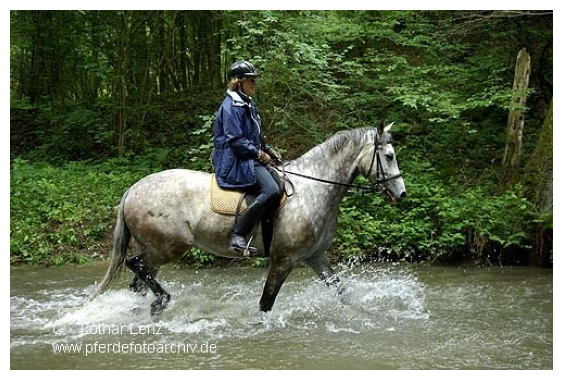

Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
MistralModel is using MistralSdpaAttention, but `torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


Response:  

 50%|█████     | 1/2 [00:16<00:16, 16.13s/it]

("[INST]  \n{question} [/INST] The image shows a person riding a horse through a body of water, which appears to be a river or stream. The rider is wearing a helmet and a brown jacket, and the horse is splashing water as it moves through the water. The surrounding environment is lush and green, suggesting a natural, possibly forested area. The watermark on the image indicates that it is from a photography website, and the photographer's name is also visible. The overall scene conveys a sense of adventure and outdoor activity. ", ((tensor([[[[1.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [9.8193e-01, 1.8280e-02, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [9.5508e-01, 3.3966e-02, 1.1055e-02,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          ...,
          [4.8096e-01, 4.4537e-04, 1.5247e-04,  ..., 1.5976e-02, 0.0000e+00, 0.0000e+00],
          [3.3667e-01, 3.9029e-04, 1.6499e-04,  ..., 1.1978e-02, 3.9444e-03, 0.0000e+00]

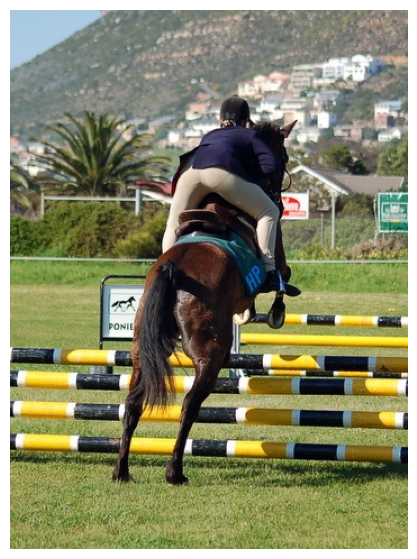

Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


Response:  

100%|██████████| 2/2 [00:35<00:00, 17.77s/it]

('[INST]  \n{question} [/INST] The image shows a person riding a horse over a series of hurdles, which are typically used in equestrian sports such as show jumping. The rider is wearing a helmet for safety, and the horse appears to be in mid-jump, with its front legs over the hurdle. The background features a landscape with houses and trees, suggesting that the event is taking place in a rural or suburban area. The rider and horse are focused on clearing the hurdle, which is a common challenge in equestrian competitions. ', ((tensor([[[[1.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [9.8193e-01, 1.8280e-02, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [9.5508e-01, 3.3966e-02, 1.1063e-02,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          ...,
          [4.4458e-01, 4.6015e-04, 1.3876e-04,  ..., 1.5121e-02, 0.0000e+00, 0.0000e+00],
          [3.0005e-01, 3.6740e-04, 1.9288e-04,  ..., 1.0727e-02, 3.5305e-03, 0.0000e+00],
   

In [ ]:
#question1 = "The image shows an image of a horse. On some images there is a watermark. Please explain if you can see a watermark in the image or not. Also explain what might seem like a watermark is just a text of the background, e.g., a sign."
#question2 = "Can you tell me, considering your explanation, if you can see a watermark on the image or not? Answer with one word of the options [yes, no]."

question1 = "The image shows an image of a horse. On some images there is a overlayed text. Please explain if you can see a overlayed text like for example a signature, or timestamp in the image or not. Also explain why it might seem like an text added in postproduction or a text of the background/the scene, e.g., a sign."
question2 = "Can you tell me, considering your explanation, if you can see an overlayed text on the image or not? Answer with one word of the options [yes, no]."


run_inference(images, num_imgs=100, question1=question1, question2=question2, data_dict=data_dict)